<a href="https://colab.research.google.com/github/ftyhanifah/Analisis-Deret-Waktu/blob/main/Tugas_Kelompok_9_Minggu_5_Simulasi_Deret_Stasioner.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TUGAS KELOMPOK: SIMULASI DERET STASIONER

**Kelompok 9**


1.   Nurqalbu Abd.Mutalip (M0501251021)
2.   Fatiya Hanifah (M0501251053)
3.   Muhammad Alief Nur Widiyanto (M0501261096)

Lakukan simulasi deret stasioner. Gunakan seed jumlah 2 digit terakhir semua anggota kelompok. (170)

Simulasikan deret MA (1) deret parameter  θ=0.6  dan panjang amatan 120.

Lakukan pembagian data latih dan data uji terhadap deret hasil simulasi (proporsi pembagian data bebas, sesuaikan dengan pola deret).

Buatlah plot ACF, PACF, dan EACF dari data latih. Identifikasi model yang tepat untuk deret simulasi berdasarkan plot-plot tersebut, kemudian lakukan pengepasan model terhadap data latij.

Lakukan pengecekan diagnostik sisaan model, overfitting, dan tentukan model terbaik berdasarkan kriteria AIC dan BIC.

Gunakan model terbaik untuk melakukan peramalan sepanjang periode data uji. Hitunglah metrik evaluasi MAPE dan RMSE dari hasil peramalan dan data latih maupun data uji. Interpretasikan apakah model yang digunakan sudah baik.

Lakukan tahapan 2-5 dengan deret simulasi yang berbeda, yaitu deret AR(2) dengan  n=100  dan parameter  ϕ1=0.9  dan  ϕ2=−0.5 ; deret ARMA(1,1) dengan  n=200  dan parameter  ϕ=0.4  dan  θ=0.6 .

Pengumpulan hasil diskusi:

melalui class.ipb.ac.id cukup perwakilan kelompok dengan format pdf. Dalam file tersebut memuat identitas anggota kelompok (Nama, NIM). Dalam file tidak perlu mencantumkan sintaks, namun menampilkan plot deret waktu dari deret simulasi dan interpretasinya; pembagian data latih data uji dan alasan pemilihan pembagian data; plot ACF, PACF, EACF, dan interpretasinya; hasil pengepasan model dan diagnostik sisaan model dan interpretasinya; plot hasil peramalan dan deret asli, nilai metrik evaluasi, dan interpretasinya.

melalui github masing-masing anggota kelompok berupa file sintaks.

In [ ]:
!pip install PythonTsa
!pip install rpy2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 441.1/441.1 kB 10.5 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import adfuller
from PythonTsa.plot_acf_pacf import acf_pacf_fig
from statsmodels.stats.diagnostic import het_arch
from statsmodels.sandbox.stats.runs import runstest_1samp
from scipy.stats import shapiro, jarque_bera
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, mean_absolute_error

import warnings
warnings.filterwarnings("ignore")

##MA (1)

## 1. Simulasi Deret MA(1)

Disimulasikan deret MA(1): $X_t = e_t + \theta e_{t-1}$ dengan $\theta = 0.6$, panjang amatan $n = 120$, dan `seed = 170`.

In [ ]:
seed = 170
np.random.seed(seed)

theta = 0.6
n = 120

#proses MA(1): koefisien MA pada ArmaProcess ditulis [1, theta]
ar = np.array([1])
ma = np.array([1, theta])
ma1_process = ArmaProcess(ar, ma)
data_sim = ma1_process.generate_sample(nsample=n)

#buat sebagai deret waktu (indeks bulanan, hanya untuk kebutuhan plotting)
timeindex = pd.date_range('2015-01', periods=n, freq='M')
deret = pd.Series(data_sim, index=timeindex, name='simulasi_ma1')
deret.head()

,simulasi_ma1
2015-01-31,0.034126
2015-02-28,-1.744018
2015-03-31,-0.419321
2015-04-30,2.837601
2015-05-31,1.426538


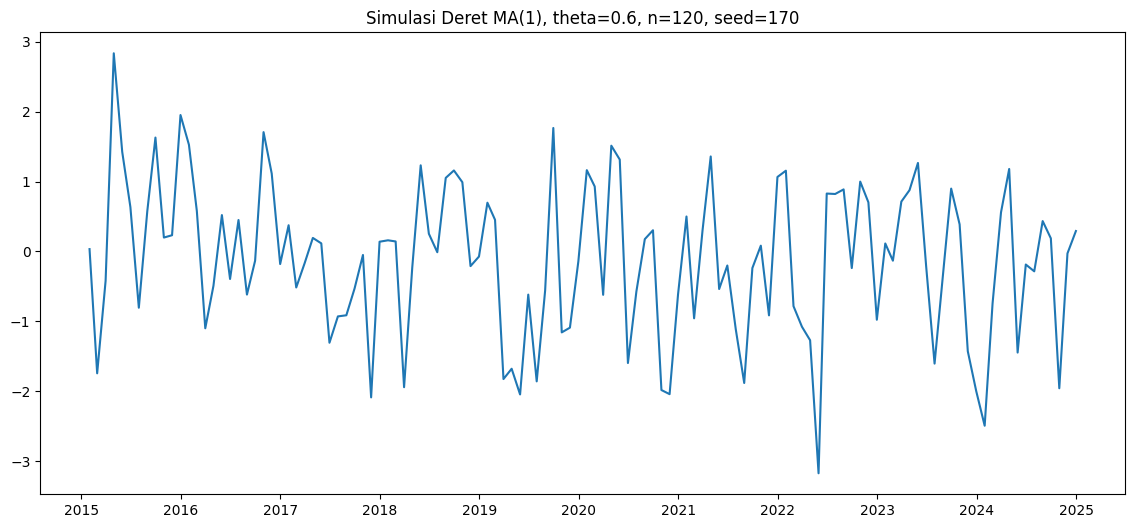

In [ ]:
#plot deret hasil simulasi
plt.figure(figsize=(14,6))
plt.plot(deret)
plt.title('Simulasi Deret MA(1), theta=0.6, n=120, seed=170')
plt.show()

**Interpretasi**

Berdasarkan plot deret waktu hasil simulasi MA(1) dengan parameter theta = 0,6 dan panjang amatan 120, nilai pengamatan terlihat berfluktuasi di sekitar rata-rata yang relatif konstan. Tidak terlihat adanya pola tren maupun perubahan varians yang sistematis sepanjang waktu. Secara visual, pola tersebut mengindikasikan bahwa deret hasil simulasi bersifat stasioner.

## 2. Pembagian Data Latih dan Data Uji

Deret hasil simulasi bersifat stasioner sejak awal (tidak ada tren maupun musiman), sehingga proporsi pembagian data bebas ditentukan. Karena panjang amatan hanya $n=120$, digunakan proporsi **80% data latih : 20% data uji** (±96 data latih dan 24 data uji)

In [ ]:
#pembagian data latih dan data uji
size_train = round(0.8*deret.shape[0])
train, test = deret[:size_train], deret[size_train:]

print('Jumlah data latih :', train.shape[0])
print('Jumlah data uji    :', test.shape[0])

Jumlah data latih : 96
Jumlah data uji    : 24


In [ ]:
train

,simulasi_ma1
2015-01-31,0.034126
2015-02-28,-1.744018
2015-03-31,-0.419321
2015-04-30,2.837601
2015-05-31,1.426538
...,...
2022-08-31,0.888933
2022-09-30,-0.237142
2022-10-31,1.000353
2022-11-30,0.704007


In [ ]:
test

,simulasi_ma1
2023-01-31,0.114861
2023-02-28,-0.131593
2023-03-31,0.714198
2023-04-30,0.878046
2023-05-31,1.267732
2023-06-30,-0.206636
2023-07-31,-1.605002
2023-08-31,-0.328038
2023-09-30,0.900145
2023-10-31,0.387903


## 3. Plot ACF, PACF, dan EACF Data Latih

In [ ]:
#cek kestasioneran data latih
adfuller(train, autolag='AIC')[1]

4.3956886189060137e-10

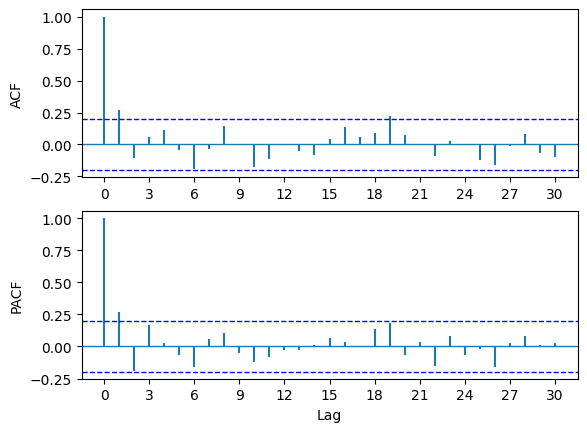

In [ ]:
#plot ACF dan PACF data latih
acf_pacf_fig(train, both=True, lag=30); plt.show()

**Identifikasi model:**

Berdasarkan plot ACF terlihat lag yang signifikan hanya pada lag 1 kemudian *cut off*, sedangkan pada plot PACF tampak *tailing off* (meluruh secara bertahap). Pola ini merupakan ciri khas proses **MA(1)**. Hasil plot EACF juga menunjukkan segitiga nol berawal pada ordo $(p=0, q=1)$, yang memperkuat dugaan model MA(1). Ordo tentatif lain yang dapat dicoba sebagai pembanding adalah AR(1), karena pada PACF lag 1 juga tampak dominan.

In [ ]:

%load_ext rpy2.ipython

In [ ]:
%%R
install.packages('TSA')
library(TSA)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
also installing the dependencies ‘xts’, ‘TTR’, ‘quadprog’, ‘zoo’, ‘quantmod’, ‘leaps’, ‘locfit’, ‘tseries’

trying URL 'https://cran.rstudio.com/src/contrib/xts_0.14.3.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/TTR_0.24.4.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/quadprog_1.5-8.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/zoo_1.9-0.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/quantmod_0.4.29.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/leaps_3.2.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/locfit_1.5-9.12.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/tseries_0.10-63.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/TSA_1.3.1.tar.gz'

The downloaded source packages are in
	‘/tmp/RtmpB8EUjW/downloaded_packages’

Attaching package: ‘TSA’

The following objects are masked from ‘package:stats’:

    acf, arima

The f

In [ ]:
%%R -i train
#membuat plot EACF dari data latih
eacf(as.numeric(train))

AR/MA
  0 1 2 3 4 5 6 7 8 9 10 11 12 13
0 x o o o o o o o o o o  o  o  o 
1 x o o o o o o o o o o  o  o  o 
2 x o x o o o o o o o o  o  o  o 
3 o x o o o o o o o o o  o  o  o 
4 x o o o o o o o o o o  o  o  o 
5 x x x o o o o o o o o  o  o  o 
6 x x o o x o o o o o o  o  o  o 
7 x x o o x o o o o o o  o  o  o 


## 4. Pengepasan Model dan Diagnostik Sisaan

In [ ]:
#model MA (1)
model_ma1 = ARIMA(train, order=(0,0,1)).fit()
print(model_ma1.summary())

                               SARIMAX Results                                
Dep. Variable:           simulasi_ma1   No. Observations:                   96
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -139.703
Date:                Wed, 23 Sep 2026   AIC                            285.407
Time:                        02:10:16   BIC                            293.100
Sample:                    01-31-2015   HQIC                           288.516
                         - 12-31-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0884      0.151     -0.587      0.557      -0.384       0.207
ma.L1          0.4064      0.105      3.875      0.000       0.201       0.612
sigma2         1.0733      0.160      6.703      0.0

Berdasarkan hasil pengepasan model ARIMA(0,0,1) pada 96 data latih, diperoleh dugaan parameter MA(1) sebesar 0,4064 dengan nilai p-value < 0,001. Karena p-value < 0,05, parameter MA(1) signifikan secara statistik, sehingga komponen MA(1) berpengaruh dalam model. Selang kepercayaan 95% untuk parameter MA(1), yaitu 0,201 hingga 0,612, juga tidak memuat nilai nol sehingga mendukung signifikansi parameter tersebut.

Konstanta model diperoleh sebesar −0,0884 dengan p-value 0,557 > 0,05, sehingga konstanta tidak signifikan secara statistik. Nilai AIC dan BIC model masing-masing sebesar 285,407 dan 293,100. Nilai tersebut selanjutnya digunakan sebagai dasar perbandingan dengan model kandidat lainnya pada tahap overfitting untuk menentukan model terbaik.

Dengan demikian, hasil pengepasan awal menunjukkan bahwa model MA(1) layak dipertimbangkan sebagai model kandidat, karena parameter MA(1) signifikan. Namun, penentuan model terbaik tetap dilakukan setelah pemeriksaan diagnostik sisaan dan perbandingan AIC serta BIC dengan model kandidat lainnya.

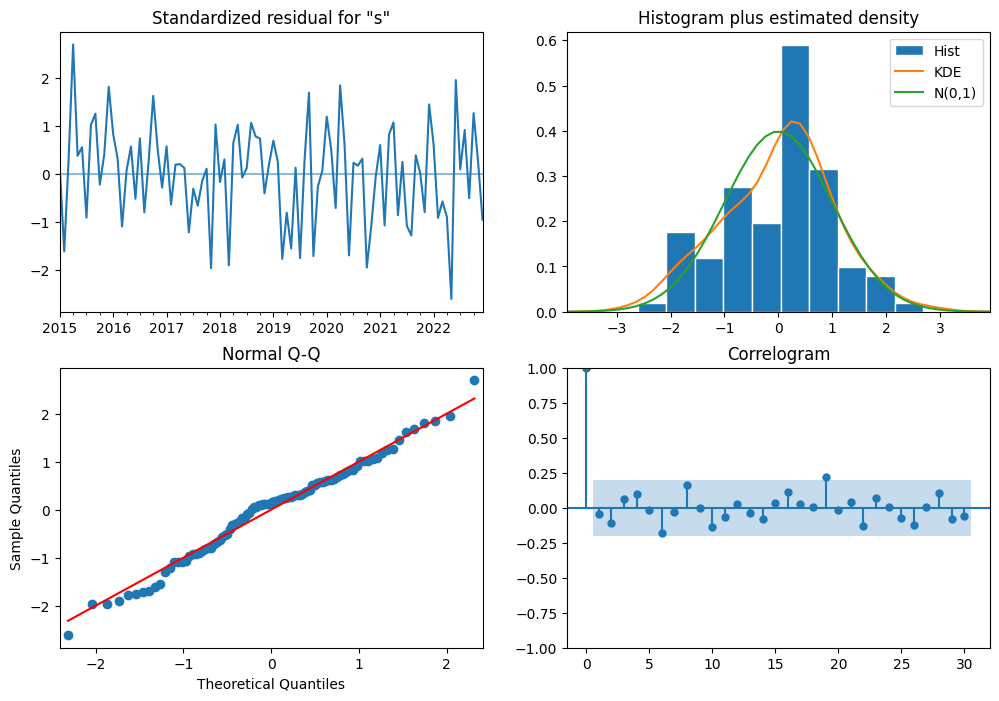

In [ ]:
#Analisis Sisaan Model MA(1)
model_ma1.plot_diagnostics(figsize=(12,8), lags=30)
plt.show()

**Interpretasi Diagnostik Sisaan Model MA(1)**

Berdasarkan plot diagnostik, standardized residual terlihat berfluktuasi secara acak di sekitar nilai nol dan tidak menunjukkan pola tren tertentu. Secara visual, penyebaran residual juga relatif konstan sepanjang waktu.

Pada histogram residual, bentuk distribusi secara umum menyerupai distribusi normal, meskipun terdapat sedikit perbedaan antara kurva kepadatan residual (KDE) dan kurva normal teoretis. Hal ini juga didukung oleh Normal Q-Q plot, di mana sebagian besar titik mengikuti garis diagonal, dengan sedikit penyimpangan terutama pada bagian ekor distribusi.

Sementara itu, pada correlogram residual, sebagian besar nilai autokorelasi residual berada di dalam batas kepercayaan. Terdapat spike pada sekitar lag 19 yang sedikit melewati batas, tetapi secara keseluruhan tidak terlihat pola autokorelasi yang sistematis pada residual.

Dengan demikian, secara visual residual model MA(1) menunjukkan karakteristik yang cukup mendekati white noise. Namun, kesimpulan mengenai pemenuhan asumsi residual selanjutnya perlu didukung oleh hasil uji diagnostik formal.

In [ ]:
model_ma1.test_heteroskedasticity('breakvar')

array([[1.29519872, 0.46850108]])

In [ ]:
het_arch(model_ma1.resid, nlags=30)[1]

np.float64(0.699276047618822)

In [ ]:
runstest_1samp(model_ma1.resid, correction=False)

(np.float64(1.4228773726795523), np.float64(0.15477170670994397))

In [ ]:
stat, p = shapiro(model_ma1.resid)
print(stat, p)

0.9856262165473062 0.38068185758709516


In [ ]:
jb_stat, jb_pval = jarque_bera(model_ma1.resid)
print(jb_stat, jb_pval)

0.5363862247626026 0.7647600822014816


Sebagai pembanding, dicobakan juga model **AR(1)** karena lag 1 pada PACF cukup dominan.

In [ ]:
#model AR (1) sebagai pembanding
model_ar1 = ARIMA(train, order=(1,0,0)).fit()
print(model_ar1.summary())

                               SARIMAX Results                                
Dep. Variable:           simulasi_ma1   No. Observations:                   96
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -141.700
Date:                Wed, 23 Sep 2026   AIC                            289.400
Time:                        02:11:28   BIC                            297.093
Sample:                    01-31-2015   HQIC                           292.510
                         - 12-31-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0896      0.149     -0.602      0.547      -0.381       0.202
ar.L1          0.2698      0.105      2.581      0.010       0.065       0.475
sigma2         1.1201      0.165      6.775      0.0

**Interpretasi Model AR(1) sebagai Model Pembanding**

Berdasarkan hasil pengepasan model AR(1) pada 96 data latih, diperoleh estimasi parameter AR(1) sebesar 0,2698 dengan p-value 0,010 < 0,05, sehingga parameter AR(1) signifikan secara statistik. Sementara itu, konstanta sebesar −0,0896 memiliki p-value 0,547 > 0,05, sehingga konstanta tidak signifikan.

Model AR(1) menghasilkan nilai AIC sebesar 289,400 dan BIC sebesar 297,093. Nilai tersebut lebih besar dibandingkan model MA(1), yang memiliki AIC 285,407 dan BIC 293,100. Karena nilai AIC dan BIC yang lebih kecil menunjukkan model yang lebih baik dalam menyeimbangkan kecocokan model dan kompleksitasnya, maka berdasarkan kedua kriteria tersebut MA(1) lebih didukung dibandingkan AR(1) untuk data latih ini.

Dengan demikian, meskipun parameter AR(1) signifikan, hasil perbandingan AIC dan BIC menunjukkan bahwa MA(1) lebih sesuai daripada AR(1) sebagai kandidat model untuk deret yang dianalisis.

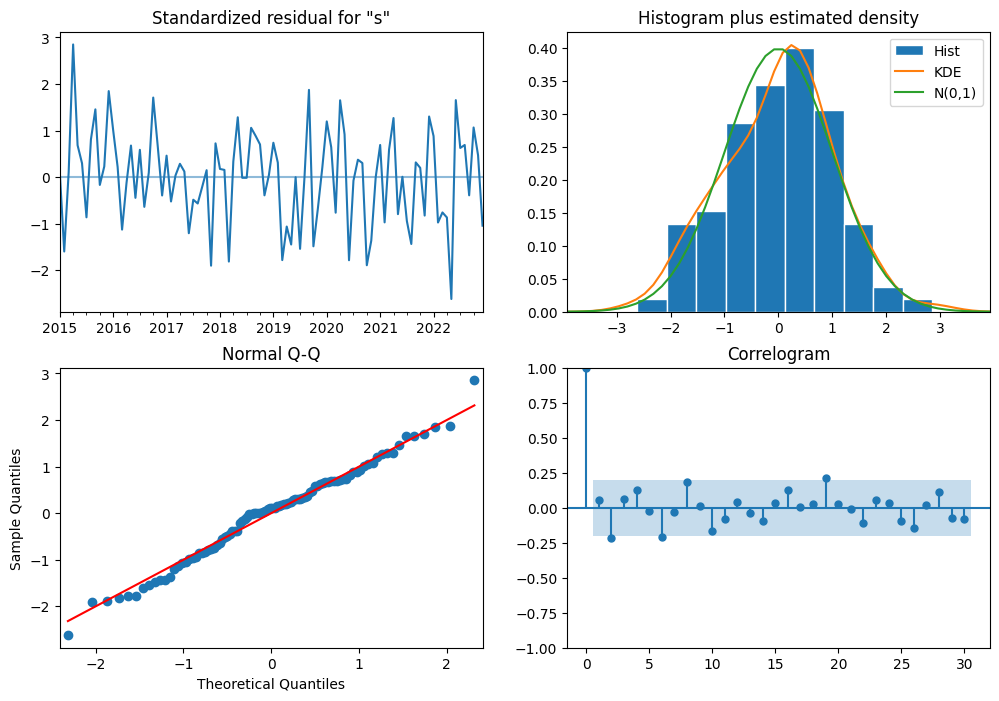

In [ ]:
#Analisis Sisaan Model AR(1)
model_ar1.plot_diagnostics(figsize=(12,8), lags=30)
plt.show()

Berdasarkan plot diagnostik model AR(1), standardized residual terlihat berfluktuasi di sekitar nol dan tidak menunjukkan adanya pola tren yang jelas. Penyebaran residual juga secara visual relatif konstan sepanjang periode pengamatan.

Pada histogram residual, distribusi residual secara umum mendekati bentuk distribusi normal. Hal ini juga terlihat pada Normal Q-Q plot, di mana sebagian besar titik berada di sekitar garis diagonal, meskipun terdapat sedikit penyimpangan pada bagian ekor distribusi.

Pada correlogram residual, sebagian besar nilai autokorelasi berada di dalam batas kepercayaan. Namun, terdapat beberapa spike pada lag tertentu yang mendekati atau sedikit melewati batas kepercayaan, sehingga secara visual masih terdapat indikasi autokorelasi residual pada beberapa lag.

Secara keseluruhan, residual model AR(1) secara visual menunjukkan karakteristik yang cukup mendekati white noise. Namun, pemenuhan asumsi residual tetap perlu dikonfirmasi menggunakan uji diagnostik formal.

In [ ]:
het_arch(model_ar1.resid, nlags=30)[1]

np.float64(0.5583741846496821)

In [ ]:
runstest_1samp(model_ar1.resid, correction=False)

(np.float64(0.9149152225436672), np.float64(0.360236137933172))

In [ ]:
stat, p = shapiro(model_ar1.resid)
print(stat, p)

0.9892061257853029 0.6294093957839666


### Overfitting

Dilakukan *overfitting* model dengan mencobakan ordo yang lebih tinggi, yaitu MA(2) dan ARMA(1,1), untuk memastikan tidak ada komponen tambahan yang signifikan.

In [ ]:
#model MA (2)
model_ma2 = ARIMA(train, order=(0,0,2)).fit()
print(model_ma2.summary())

                               SARIMAX Results                                
Dep. Variable:           simulasi_ma1   No. Observations:                   96
Model:                 ARIMA(0, 0, 2)   Log Likelihood                -139.058
Date:                Wed, 23 Sep 2026   AIC                            286.116
Time:                        02:11:41   BIC                            296.374
Sample:                    01-31-2015   HQIC                           290.263
                         - 12-31-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0870      0.138     -0.631      0.528      -0.357       0.183
ma.L1          0.3550      0.111      3.210      0.001       0.138       0.572
ma.L2         -0.1101      0.101     -1.090      0.2

**Interpretasi Hasil Overfitting Model MA(2)**

Berdasarkan hasil pengepasan model MA(2), parameter MA(1) diperoleh sebesar 0,3550 dengan p-value 0,001 < 0,05, sehingga parameter tersebut signifikan secara statistik. Sementara itu, parameter MA(2) sebesar −0,1101 memiliki p-value 0,276 > 0,05, sehingga parameter MA pada lag ke-2 tidak signifikan. Konstanta sebesar −0,0870 juga tidak signifikan dengan p-value 0,528 > 0,05.

Model MA(2) menghasilkan AIC sebesar 286,116 dan BIC sebesar 296,374. Dibandingkan dengan model MA(1), yang memiliki AIC sebesar 285,407 dan BIC sebesar 293,100, model MA(2) memiliki nilai AIC dan BIC yang lebih besar. Dengan demikian, penambahan parameter MA pada lag ke-2 tidak memberikan perbaikan model yang cukup untuk mengimbangi bertambahnya kompleksitas model.

Berdasarkan ketidaksignifikanan parameter MA(2) serta nilai AIC dan BIC yang lebih besar, model MA(2) tidak menunjukkan peningkatan dibandingkan model MA(1). Oleh karena itu, hasil overfitting ini mendukung penggunaan model MA(1) yang lebih sederhana.

In [ ]:
#model ARMA (1,1)
model_arma11 = ARIMA(train, order=(1,0,1)).fit()
print(model_arma11.summary())

                               SARIMAX Results                                
Dep. Variable:           simulasi_ma1   No. Observations:                   96
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -139.146
Date:                Wed, 23 Sep 2026   AIC                            286.292
Time:                        02:11:45   BIC                            296.549
Sample:                    01-31-2015   HQIC                           290.438
                         - 12-31-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0876      0.142     -0.617      0.537      -0.366       0.190
ar.L1         -0.2309      0.251     -0.922      0.357      -0.722       0.260
ma.L1          0.5926      0.204      2.904      0.0

**Interpretasi Hasil Overfitting Model ARMA(1,1)**

Berdasarkan hasil pengepasan model ARMA(1,1), diperoleh estimasi parameter AR(1) sebesar −0,2309 dengan p-value 0,357 > 0,05, sehingga parameter AR(1) tidak signifikan secara statistik. Sementara itu, parameter MA(1) sebesar 0,5926 memiliki p-value 0,004 < 0,05, sehingga parameter MA(1) signifikan secara statistik. Konstanta sebesar −0,0876 juga tidak signifikan dengan p-value 0,537 > 0,05.

Model ARMA(1,1) menghasilkan nilai AIC sebesar 286,292 dan BIC sebesar 296,549. Nilai tersebut lebih besar dibandingkan model MA(1), yang memiliki AIC sebesar 285,407 dan BIC sebesar 293,100. Dengan demikian, penambahan komponen AR(1) pada model tidak memberikan perbaikan yang cukup untuk mengimbangi peningkatan kompleksitas model.

Berdasarkan ketidaksignifikanan parameter AR(1), signifikannya parameter MA(1), serta nilai AIC dan BIC yang lebih besar dibandingkan MA(1), model ARMA(1,1) tidak menunjukkan peningkatan dibandingkan model MA(1). Hasil overfitting ini kembali mendukung penggunaan model MA(1) yang lebih sederhana.

### Pemilihan Model Terbaik (AIC dan BIC)

In [ ]:
pd.DataFrame({'Model':['MA(1)','AR(1)','MA(2)','ARMA(1,1)'],
              'AIC':[model_ma1.aic, model_ar1.aic, model_ma2.aic, model_arma11.aic],
              'BIC':[model_ma1.bic, model_ar1.bic, model_ma2.bic, model_arma11.bic]})

,Model,AIC,BIC
0,MA(1),285.406651,293.099695
1,AR(1),289.400161,297.093206
2,MA(2),286.116456,296.373849
3,"ARMA(1,1)",286.291667,296.549059


**Interpretasi Pemilihan Model Terbaik Berdasarkan AIC dan BIC**

Berdasarkan perbandingan empat model kandidat, model MA(1) memiliki nilai AIC sebesar 285,407 dan BIC sebesar 293,100, yang merupakan nilai paling rendah dibandingkan model AR(1), MA(2), dan ARMA(1,1). Model MA(2) memiliki AIC 286,116 dan BIC 296,374, ARMA(1,1) memiliki AIC 286,292 dan BIC 296,549, sedangkan AR(1) memiliki AIC 289,400 dan BIC 297,093.

Karena model dengan nilai AIC dan BIC yang lebih kecil lebih didukung berdasarkan kriteria tersebut, maka MA(1) dipilih sebagai model terbaik di antara model kandidat yang dibandingkan. Pemilihan ini juga konsisten dengan hasil identifikasi awal melalui ACF dan PACF serta hasil overfitting, di mana penambahan parameter pada model MA(2) dan ARMA(1,1) tidak memberikan peningkatan yang memadai.
Oleh karena itu, model MA(1) selanjutnya digunakan untuk melakukan peramalan pada periode data uji.

## 5. Peramalan dan Evaluasi Model

In [ ]:
#peramalan sepanjang periode data uji menggunakan model terbaik (MA(1))
prediksi_test = model_ma1.get_forecast(test.shape[0]).summary_frame(alpha=0.05)
prediksi_test

simulasi_ma1,mean,mean_se,mean_ci_lower,mean_ci_upper
2023-01-31,-0.492858,1.035994,-2.523369,1.537653
2023-02-28,-0.088401,1.118261,-2.280151,2.103349
2023-03-31,-0.088401,1.118261,-2.280151,2.103349
2023-04-30,-0.088401,1.118261,-2.280151,2.103349
2023-05-31,-0.088401,1.118261,-2.280151,2.103349
2023-06-30,-0.088401,1.118261,-2.280151,2.103349
2023-07-31,-0.088401,1.118261,-2.280151,2.103349
2023-08-31,-0.088401,1.118261,-2.280151,2.103349
2023-09-30,-0.088401,1.118261,-2.280151,2.103349
2023-10-31,-0.088401,1.118261,-2.280151,2.103349


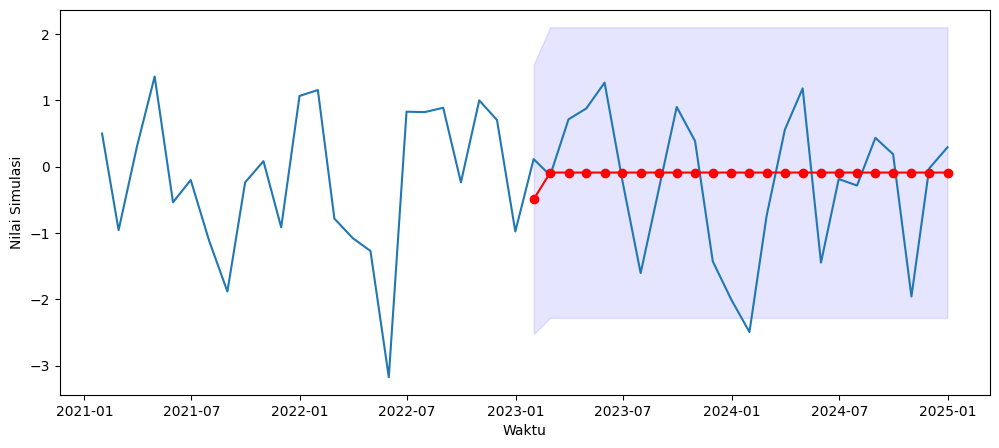

In [ ]:
#plot perbandingan data aktual dan hasil peramalan
plt.figure(figsize=(12,5))
plt.plot(deret[-48:])
plt.plot(prediksi_test['mean'], '-or')
plt.fill_between(prediksi_test.index, prediksi_test['mean_ci_lower'], prediksi_test['mean_ci_upper'], color='b', alpha=.1)
plt.xlabel('Waktu'), plt.ylabel('Nilai Simulasi')
plt.show()

**Interpretasi Hasil Peramalan Model MA(1)**

Berdasarkan plot perbandingan data aktual dan hasil peramalan, nilai aktual pada periode data uji masih menunjukkan fluktuasi yang cukup besar di sekitar rata-rata. Sementara itu, hasil peramalan model MA(1) pada awal periode masih dipengaruhi oleh informasi residual sebelumnya, kemudian dengan cepat bergerak mendekati nilai rata-rata proses dan relatif konstan pada periode-periode berikutnya.

Pola tersebut sesuai dengan karakteristik model MA(1), karena nilai pada suatu periode hanya dipengaruhi oleh galat pada periode saat ini dan satu periode sebelumnya. Oleh karena itu, untuk peramalan beberapa langkah ke depan, pengaruh galat sebelumnya segera hilang dan ramalan akan mendekati rata-rata model.

Interval prediksi 95% terlihat cukup lebar dan sebagian besar nilai aktual berada di dalam interval tersebut. Hal ini menunjukkan adanya ketidakpastian yang cukup besar dalam peramalan nilai individual pada periode data uji. Dengan demikian, kemampuan peramalan model belum dapat dinilai hanya berdasarkan grafik, sehingga perlu dilanjutkan dengan evaluasi kuantitatif menggunakan MAPE dan RMSE pada data latih dan data uji.

In [ ]:
#evaluasi pada data uji
mape_test = mean_absolute_percentage_error(test, prediksi_test['mean'])*100
rmse_test = np.sqrt(mean_squared_error(test, prediksi_test['mean']))
mae_test  = mean_absolute_error(test, prediksi_test['mean'])

print('MAPE (data uji): ', mape_test, '%')
print('RMSE (data uji): ', rmse_test)
print('MAE  (data uji): ', mae_test)

MAPE (data uji):  119.93932274819177 %
RMSE (data uji):  1.0596333541987202
MAE  (data uji):  0.8378908023464442


In [ ]:
#evaluasi pada data latih (nilai teramal/fitted vs aktual)
fitted_train = model_ma1.fittedvalues

mape_train = mean_absolute_percentage_error(train, fitted_train)*100
rmse_train = np.sqrt(mean_squared_error(train, fitted_train))
mae_train  = mean_absolute_error(train, fitted_train)

print('MAPE (data latih): ', mape_train, '%')
print('RMSE (data latih): ', rmse_train)
print('MAE  (data latih): ', mae_train)

MAPE (data latih):  124.59189392079033 %
RMSE (data latih):  1.0363660515118207
MAE  (data latih):  0.8207895457407998


**Interpretasi:**

Berdasarkan hasil evaluasi, diperoleh MAPE sebesar 124,59% dan RMSE sebesar 1,0364 pada data latih, sedangkan pada data uji diperoleh MAPE sebesar 119,94% dan RMSE sebesar 1,0596. Nilai RMSE pada data latih dan data uji relatif berdekatan, sehingga tidak terlihat peningkatan kesalahan yang besar ketika model digunakan pada data uji.

Nilai MAPE yang melebihi 100% perlu diinterpretasikan secara hati-hati karena deret simulasi MA(1) berfluktuasi di sekitar nol dan memiliki nilai aktual yang dapat mendekati nol. Pada kondisi tersebut, penyebut dalam perhitungan MAPE menjadi sangat kecil sehingga persentase kesalahan dapat menjadi sangat besar. Oleh karena itu, nilai MAPE pada kasus ini kurang stabil dan tidak digunakan sebagai satu-satunya dasar untuk menilai kinerja model.

Penilaian model selanjutnya dilakukan dengan mempertimbangkan RMSE bersama dengan hasil diagnostik sisaan serta kriteria AIC dan BIC. Nilai RMSE data latih (1,0364) dan data uji (1,0596) relatif serupa, sedangkan pada tahap pemilihan model, MA(1) memiliki nilai AIC dan BIC paling rendah dibandingkan model kandidat yang diuji. Dengan demikian, hasil evaluasi mendukung penggunaan MA(1) sebagai model terpilih untuk deret simulasi yang dianalisis, dengan tetap memperhatikan keterbatasan MAPE pada data yang berfluktuasi di sekitar nol.

## AR(2)

### 1. Simulasikan deret AR(2) dengan $n=100$ dan parameter $\phi_1=0.9$ dan $\phi_2=-0.5$

In [ ]:
from statsmodels.tsa.arima_process import ArmaProcess

In [ ]:
np.random.seed(170)

phi1 = 0.9
phi2 = -0.5
n_ar = 100

proses_ar2 = ArmaProcess(
    ar=[
        1,
        -phi1,
        -phi2
    ],
    ma=[1]
)

sim_ar2 = proses_ar2.generate_sample(
    nsample=n_ar
)

sim_ar2 = pd.Series(
    sim_ar2,
    name='AR2'
)

In [ ]:
import matplotlib.pyplot as plt

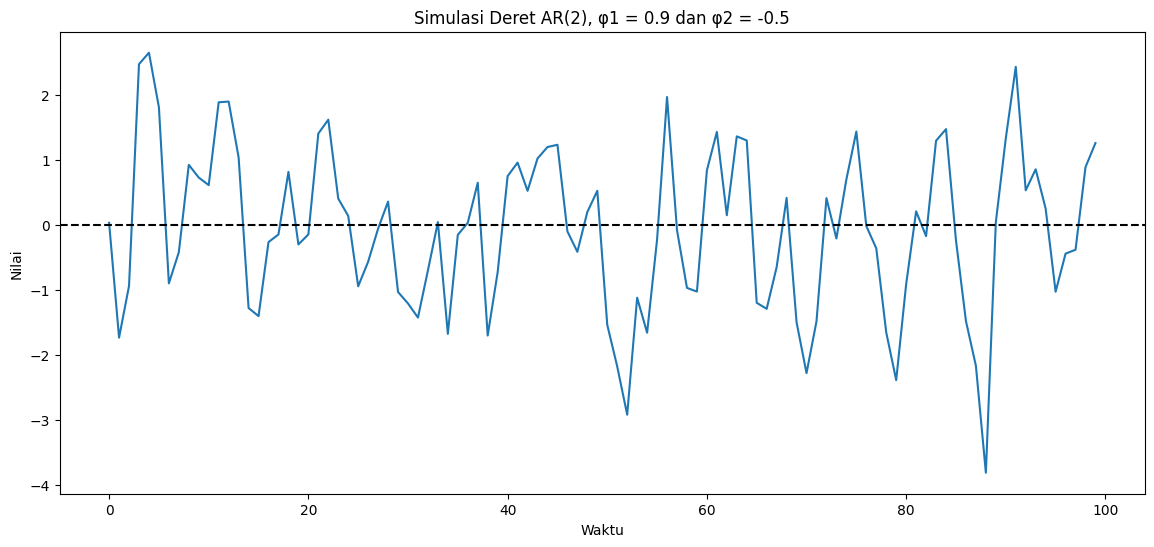

In [ ]:
plt.figure(figsize=(14,6))
plt.plot(sim_ar2)
plt.axhline(0, color='black', linestyle='--')

plt.title(
    'Simulasi Deret AR(2), '
    'φ1 = 0.9 dan φ2 = -0.5'
)

plt.xlabel('Waktu')
plt.ylabel('Nilai')
plt.show()

Plot deret waktu hasil simulasi AR(2) menunjukkan data berfluktuasi di sekitar nilai tengah yang relatif konstan tanpa adanya trend yang sistematis. Variabilitas deret juga terlihat relatif stabil sepanjang periode pengamatan. Secara visual, pola tersebut mengindikasikan bahwa deret bersifat stasioner.

### 2. Lakukan pembagian data latih dan data uji terhadap deret hasil simulasi (proporsi pembagian data bebas, sesuaikan dengan pola deret).

In [ ]:
size_train_ar = round(
    0.8 * sim_ar2.shape[0]
)

train_ar = sim_ar2[:size_train_ar]
test_ar = sim_ar2[size_train_ar:]

print("Jumlah train :", train_ar.shape[0])
print("Jumlah test  :", test_ar.shape[0])

Jumlah train : 80
Jumlah test  : 20


In [ ]:
adfuller(
    train_ar,
    autolag='AIC'
)[1]

4.211853039969555e-07

Hasil uji Augmented Dickey-Fuller menghasilkan p-value sebesar  4.21×10−7 , lebih kecil dari taraf nyata 5%. Dengan demikian,  H0  ditolak sehingga terdapat bukti bahwa data latih AR(2) telah stasioner. Oleh karena itu, deret dapat langsung dimodelkan tanpa proses differencing.

### 3. Buatlah plot ACF, PACF, dan EACF dari data latih. Identifikasi model yang tepat untuk deret simulasi berdasarkan plot-plot tersebut, kemudian lakukan pengepasan model terhadap data latih.

ACF, PACF dan EACF AR(2)

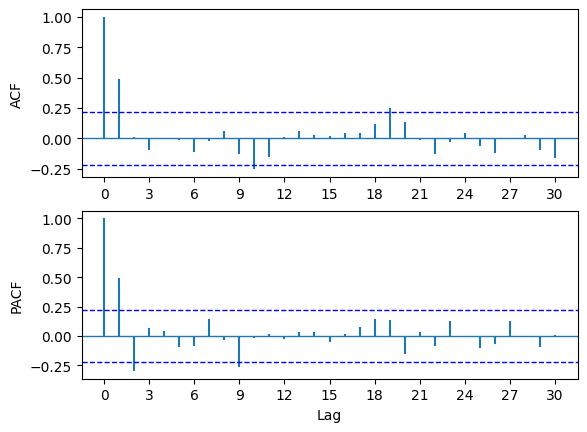

In [ ]:
acf_pacf_fig(
    train_ar,
    both=True,
    lag=30
)

plt.show()

Plot ACF menunjukkan autokorelasi yang cukup besar pada lag pertama, kemudian cenderung mengecil dan berfluktuasi di sekitar nol pada lag-lag berikutnya. Sementara itu, plot PACF menunjukkan spike yang signifikan pada lag 1 dan lag 2, kemudian sebagian besar nilai PACF berada dalam interval kepercayaan. Pola PACF yang mengalami cut-off setelah lag 2 mengindikasikan bahwa model AR(2) merupakan kandidat yang sesuai untuk deret simulasi.

In [ ]:
%%R -i train_ar
eacf(as.numeric(train_ar))

AR/MA
  0 1 2 3 4 5 6 7 8 9 10 11 12 13
0 x o o o o o o o o x o  o  o  o 
1 x o o o o o o o o o o  o  o  o 
2 o o o o o o o o o o o  o  o  o 
3 x o o o o o o o o o o  o  o  o 
4 x x o o o o o o o o o  o  o  o 
5 x x x o o o o o o o o  o  o  o 
6 x x x o o o o o o o o  o  o  o 
7 x x x o o o o o o o o  o  o  o 


Hasil EACF menunjukkan pola $o$ yang mendukung titik $(p,q)=(2,0)$. Hasil ini konsisten dengan identifikasi berdasarkan PACF, sehingga model tentatif yang dipilih adalah AR(2).

Fitting AR(2)

In [ ]:
train_ar2 = ARIMA(
    train_ar,
    order=(2,0,0)
).fit()

print(
    train_ar2.summary()
)

                               SARIMAX Results                                
Dep. Variable:                    AR2   No. Observations:                   80
Model:                 ARIMA(2, 0, 0)   Log Likelihood                -112.929
Date:                Wed, 23 Sep 2026   AIC                            233.858
Time:                        03:06:35   BIC                            243.386
Sample:                             0   HQIC                           237.678
                                 - 80                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0813      0.176     -0.462      0.644      -0.426       0.264
ar.L1          0.6617      0.127      5.212      0.000       0.413       0.911
ar.L2         -0.3176      0.112     -2.828      0.0

Hasil pengepasan model AR(2) menghasilkan koefisien AR(1) sebesar 0.6617 dan AR(2) sebesar -0.3176. Kedua parameter signifikan pada taraf nyata 5% dengan p-value masing-masing <0.001 dan 0.005. Tanda koefisien hasil estimasi juga sesuai dengan parameter pembangkit, yaitu koefisien lag pertama positif dan lag kedua negatif. Perbedaan nilai estimasi dengan parameter sebenarnya  (0.9;−0.5)  merupakan hal yang wajar karena estimasi dilakukan berdasarkan sampel sebanyak 80 observasi dan dipengaruhi oleh variasi acak hasil simulasi.

Sementara itu, konstanta memiliki p-value sebesar 0.644 sehingga tidak signifikan. Hal ini sejalan dengan proses simulasi yang berfluktuasi di sekitar nilai tengah nol.

## 4. Lakukan pengecekan diagnostik sisaan model, overfitting, dan tentukan model terbaik berdasarkan kriteria AIC dan BIC.

Diagnostik Residual AR(2)

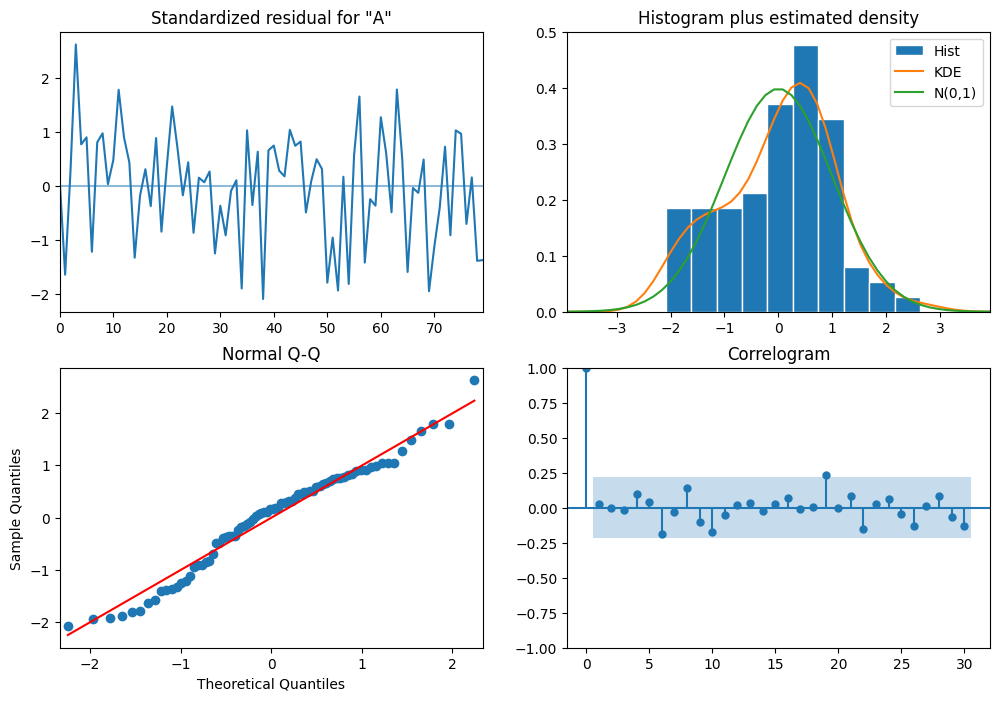

In [ ]:
train_ar2.plot_diagnostics(
    figsize=(12,8),
    lags=30
)

plt.show()

Residual model AR(2) berfluktuasi di sekitar nol dengan variasi yang relatif stabil. Histogram dan Q-Q plot menunjukkan residual cukup mendekati distribusi normal, sedangkan correlogram menunjukkan sebagian besar autokorelasi residual berada dalam interval kepercayaan. Secara visual, tidak terlihat pelanggaran asumsi residual yang kuat.

Pemeriksaan Heteroskedastisitas

In [ ]:
train_ar2.test_heteroskedasticity(
    'breakvar'
)

array([[1.15290585, 0.71428327]])

Uji heteroskedastisitas menghasilkan p-value sebesar 0.7143, lebih besar dari 0.05. Dengan demikian, tidak terdapat bukti heteroskedastisitas yang signifikan pada residual. Varians residual dapat dianggap relatif konstan.

Uji ARCH

In [ ]:
het_arch(
    train_ar2.resid,
    nlags=30
)[1]

np.float64(0.8016801872511387)

Uji ARCH menghasilkan p-value sebesar 0.8017 > 0.05 sehingga gagal menolak $H_0$. Dengan demikian, tidak terdapat bukti adanya efek ARCH pada residual. Hal ini mendukung asumsi bahwa varians residual relatif stabil dari waktu ke waktu.

Runs Test

In [ ]:
runstest_1samp(
    train_ar2.resid,
    correction=False
)

(np.float64(0.43753850651939274), np.float64(0.6617208566015469))

Runs test menghasilkan p-value sebesar 0.6617, lebih besar dari 0.05. Dengan demikian, tidak terdapat bukti adanya pola nonacak yang signifikan pada residual. Residual dapat dianggap memiliki pola yang cukup acak.

Normalitas Residual

In [ ]:
stat, p = shapiro(
    train_ar2.resid
)

print(stat, p)

0.9714370927988054 0.07009204928575706


Uji Shapiro-Wilk menghasilkan p-value sebesar 0.0701 dan uji Jarque-Bera menghasilkan p-value sebesar 0.61. Kedua nilai tersebut lebih besar dari 0.05 sehingga gagal menolak hipotesis nol normalitas. Dengan demikian, tidak terdapat bukti yang cukup bahwa residual menyimpang dari distribusi normal. Hasil ini juga konsisten dengan histogram dan Q-Q plot residual.

Autokorelasi Residual

Pada output ```summary()```:

$$ Prob(Q)=0.83>0.05. $$

Ini merupakan Ljung-Box pada lag 1.

Uji Ljung-Box pada lag 1 menghasilkan p-value sebesar 0.83 > 0.05 sehingga tidak terdapat bukti autokorelasi residual yang signifikan pada lag tersebut. Correlogram residual juga menunjukkan sebagian besar autokorelasi berada dalam interval kepercayaan.

Secara keseluruhan, hasil diagnostik memberikan indikasi bahwa residual telah cukup memenuhi asumsi model.

Overfitting AR(2)

coba AR(3):

In [ ]:
train_ar3 = ARIMA(
    train_ar,
    order=(3,0,0)
).fit()

coba ARMA (2,1):

In [ ]:
train_arma21_ar = ARIMA(
    train_ar,
    order=(2,0,1)
).fit()

Perbandingan

In [ ]:
pd.DataFrame({
    'Model': [
        'AR(2)',
        'AR(3)',
        'ARMA(2,1)'
    ],

    'AIC': [
        train_ar2.aic,
        train_ar3.aic,
        train_arma21_ar.aic
    ],

    'BIC': [
        train_ar2.bic,
        train_ar3.bic,
        train_arma21_ar.bic
    ]
})

,Model,AIC,BIC
0,AR(2),233.858166,243.386272
1,AR(3),235.477684,247.387818
2,"ARMA(2,1)",235.613739,247.523872


Pemeriksaan overfitting dilakukan dengan membandingkan AR(2) dengan model yang lebih kompleks, yaitu AR(3) dan ARMA(2,1). AR(2) menghasilkan AIC sebesar 233.858 dan BIC sebesar 243.386, keduanya lebih kecil daripada model overfitting. Meskipun selisih AIC relatif kecil, BIC memberikan dukungan lebih jelas terhadap AR(2) dan model tersebut juga lebih parsimonious. Dengan mempertimbangkan hasil ACF, PACF, EACF, signifikansi parameter, diagnostik residual, serta AIC dan BIC, AR(2) dipilih sebagai model terbaik.

## 5. Gunakan model terbaik untuk melakukan peramalan sepanjang periode data uji. Hitunglah metrik evaluasi MAPE dan RMSE dari hasil peramalan dan data latih maupun data uji. Interpretasikan apakah model yang digunakan sudah baik.

In [ ]:
prediksi_ar = (
    train_ar2
    .get_forecast(
        test_ar.shape[0]
    )
    .summary_frame(
        alpha=0.05
    )
)

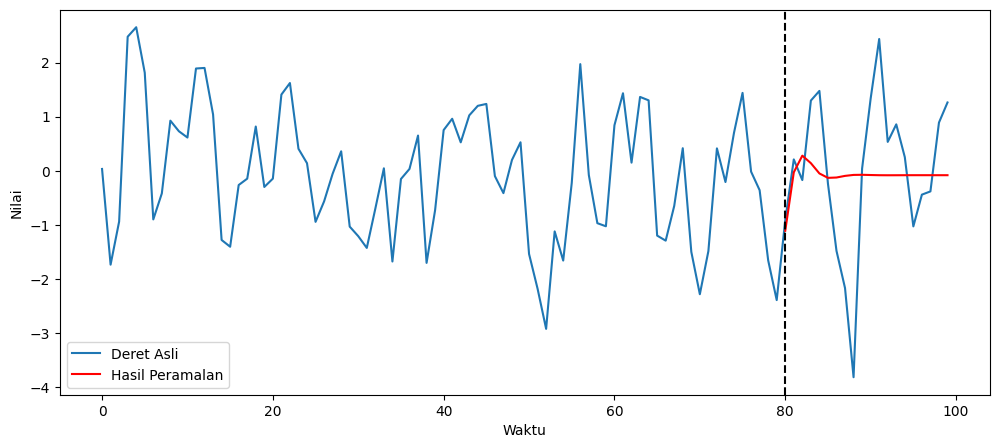

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    sim_ar2,
    label='Deret Asli'
)

plt.plot(
    prediksi_ar['mean'],
    color='red',
    label='Hasil Peramalan'
)

plt.axvline(
    x=size_train_ar,
    color='black',
    linestyle='--'
)

plt.xlabel('Waktu')
plt.ylabel('Nilai')
plt.legend()
plt.show()

In [ ]:
pred_train_ar = train_ar2.fittedvalues

mape_train_ar = (
    mean_absolute_percentage_error(
        train_ar,
        pred_train_ar
    ) * 100
)

rmse_train_ar = np.sqrt(
    mean_squared_error(
        train_ar,
        pred_train_ar
    )
)

mape_test_ar = (
    mean_absolute_percentage_error(
        test_ar,
        prediksi_ar['mean']
    ) * 100
)

rmse_test_ar = np.sqrt(
    mean_squared_error(
        test_ar,
        prediksi_ar['mean']
    )
)

print('MAPE Train:', mape_train_ar, '%')
print('RMSE Train:', rmse_train_ar)

print('MAPE Test :', mape_test_ar, '%')
print('RMSE Test :', rmse_test_ar)

MAPE Train: 203.24694826564428 %
RMSE Train: 0.9914733575369178
MAPE Test : 111.50634885634842 %
RMSE Test : 1.3719007487203152


RMSE pada data latih sebesar 0.9915, sedangkan pada data uji sebesar 1.3719. Nilai RMSE yang lebih besar pada data uji menunjukkan bahwa kesalahan meningkat ketika model digunakan untuk meramalkan observasi yang tidak digunakan dalam proses estimasi. Namun, hal tersebut masih dapat terjadi pada proses stokastik karena nilai masa depan dipengaruhi oleh inovasi acak yang tidak dapat diprediksi.

Nilai MAPE pada data latih dan data uji masing-masing sebesar 203.25% dan 111.51%. Nilai yang sangat besar ini tidak dapat langsung diartikan bahwa model memiliki kemampuan peramalan yang buruk. Deret hasil simulasi AR(2) berfluktuasi di sekitar nol serta mengandung nilai positif dan negatif. Karena MAPE menggunakan nilai aktual sebagai penyebut, observasi yang mendekati nol dapat menghasilkan persentase kesalahan yang sangat besar. Oleh karena itu, pada kasus ini MAPE kurang representatif dan evaluasi akurasi lebih tepat ditekankan pada RMSE.

## ARMA (1,1)

In [ ]:
# Import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.arima.model import ARIMA

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import het_arch
from statsmodels.sandbox.stats.runs import runstest_1samp
from scipy.stats import shapiro

In [ ]:
# Seed = 2 digit terakhir jumlah anggota kelompok
seed = 170

# Parameter ARMA(1,1)
phi = 0.4
theta = 0.6

# Panjang deret
n = 200

np.random.seed(seed)

# 1. Deret ARMA(1,1) dengan  n=200  dan parameter  ϕ=0.4  dan  θ=0.6 .

In [ ]:
# Komponen AR(1)
ar = np.array([1, -phi])

# Komponen MA(1)
ma = np.array([1, theta])

# Membentuk proses ARMA(1,1)
model_arma11 = ArmaProcess(ar, ma)

# Simulasi data
data_arma11 = model_arma11.generate_sample(
    nsample=n,
    scale=1,
    distrvs=np.random.normal
)

# Membuat DataFrame
df_arma11 = pd.DataFrame({
    'Y': data_arma11
})

df_arma11.head()

,Y
0,0.034126
1,-1.730368
2,-1.111468
3,2.393014
4,2.383743


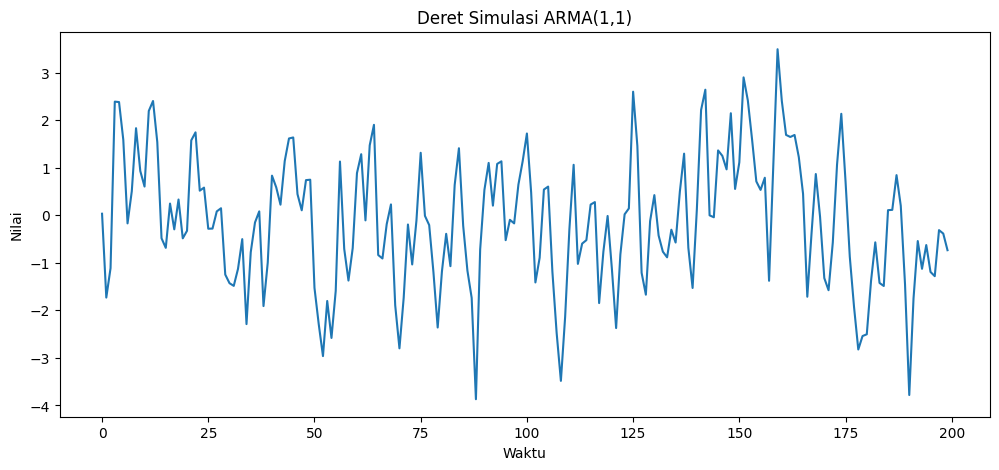

In [ ]:
# Plot Deret
plt.figure(figsize=(12, 5))

plt.plot(df_arma11['Y'])

plt.title('Deret Simulasi ARMA(1,1)')
plt.xlabel('Waktu')
plt.ylabel('Nilai')

plt.show()

**Intepretasi:** Plot deret hasil simulasi ARMA(1,1) menunjukkan pola fluktuasi di sekitar nilai rata-rata nol, tanpa terlihat adanya tren naik maupun turun sepanjang waktu pengamatan. Deret bergerak naik-turun secara acak dengan amplitudo yang relatif konsisten sepanjang periode 0 hingga 200, tidak menunjukkan pola musiman maupun perubahan variansi yang signifikan dari waktu ke waktu. Karakteristik ini mengindikasikan bahwa deret bersifat stasioner, baik dalam rata-rata maupun ragam, sesuai dengan teori bahwa proses ARMA(1,1) dengan |φ|<1 merupakan proses yang stasioner. Pola pergerakan yang tampak juga konsisten dengan karakteristik komponen MA yang memberikan efek "smoothing" jangka pendek pada guncangan, sehingga fluktuasi antar titik waktu yang berdekatan tidak sepenuhnya independen.

# 2. Lakukan pembagian data latih dan data uji terhadap deret hasil simulasi (proporsi pembagian data bebas, sesuaikan dengan pola deret)

Jumlah data : 200
Data latih  : 160
Data uji    : 40


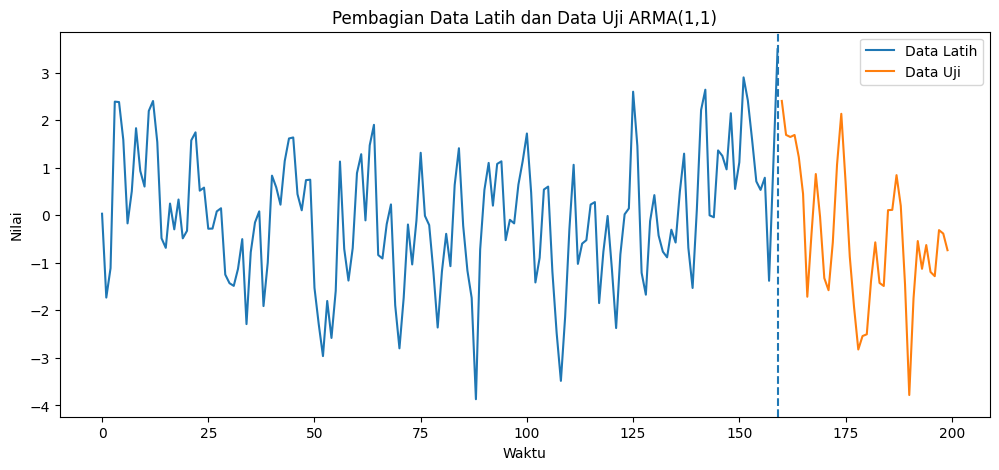

In [ ]:
# Pembagian data latih dan data uji
n_train = 160

train_arma11 = df_arma11['Y'].iloc[:n_train]
test_arma11 = df_arma11['Y'].iloc[n_train:]

print("Jumlah data :", len(df_arma11))
print("Data latih  :", len(train_arma11))
print("Data uji    :", len(test_arma11))

plt.figure(figsize=(12, 5))

plt.plot(train_arma11.index, train_arma11,
         label='Data Latih')

plt.plot(test_arma11.index, test_arma11,
         label='Data Uji')

plt.axvline(x=n_train-1, linestyle='--')

plt.title('Pembagian Data Latih dan Data Uji ARMA(1,1)')
plt.xlabel('Waktu')
plt.ylabel('Nilai')
plt.legend()

plt.show()

Alasan : Berdasarkan plot deret waktu, pola data relatif konsisten sepanjang periode pengamatan dan tidak menunjukkan perubahan tren yang mencolok. Oleh karena itu, data dibagi secara kronologis dengan proporsi 80% data latih dan 20% data uji, sehingga diperoleh 160 data latih dan 40 data uji.

# 3. Buatlah plot ACF, PACF, dan EACF dari data latih. Identifikasi model yang tepat untuk deret simulasi berdasarkan plot-plot tersebut, kemudian lakukan pengepasan model terhadap data latij.

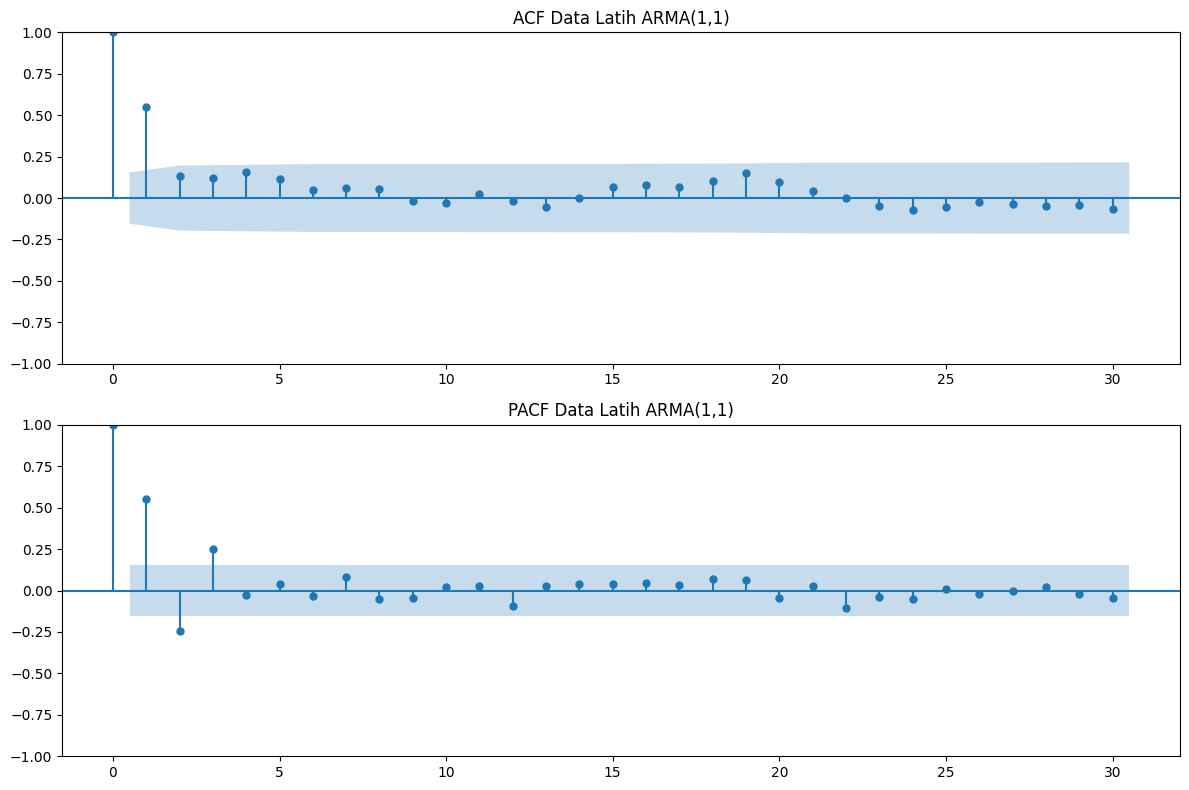

In [ ]:
# Plot ACF dan PACF
train_arma11 = df_arma11['Y'].iloc[:160]
test_arma11 = df_arma11['Y'].iloc[160:]

# Plot ACF dan PACF data latih
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# ACF
plot_acf(
    train_arma11,
    lags=30,
    alpha=0.05,
    ax=axes[0]
)
axes[0].set_title('ACF Data Latih ARMA(1,1)')

# PACF
plot_pacf(
    train_arma11,
    lags=30,
    alpha=0.05,
    ax=axes[1]
)
axes[1].set_title('PACF Data Latih ARMA(1,1)')

plt.tight_layout()
plt.show()

Berdasarkan plot ACF data latih, terlihat bahwa ACF pada lag 1 bernilai positif dan signifikan, kemudian nilai autokorelasi pada lag berikutnya menurun dan sebagian besar berada dalam batas signifikansi. Pola tersebut menunjukkan adanya ketergantungan antar-pengamatan pada beberapa lag awal yang kemudian melemah, sehingga mengarah pada adanya komponen MA dan pola yang sesuai dengan proses ARMA.

Berdasarkan plot PACF data latih, terlihat bahwa lag 1, lag 2, dan lag 3 berada di luar batas signifikansi, sedangkan sebagian besar lag setelah lag 3 berada dalam batas signifikansi. Hal ini menunjukkan adanya hubungan parsial yang signifikan hingga lag 3, sehingga plot PACF memberikan indikasi adanya komponen AR dengan orde hingga 3.

### EACF

In [ ]:
!pip install rpy2

In [ ]:
import warnings
warnings.filterwarnings("ignore")

#Jalankan syntax ini cukup satu kali, jangan berulang
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [ ]:
%%R
install.packages('TSA')
library (TSA)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cran.rstudio.com/src/contrib/TSA_1.3.1.tar.gz'
Content type 'application/x-gzip' length 207505 bytes (202 KB)
downloaded 202 KB


The downloaded source packages are in
	‘/tmp/RtmpB8EUjW/downloaded_packages’


In [ ]:
%%R -i train_arma11
#membuat plot EACF dari data latih ARMA(1,1)
eacf(as.numeric(train_arma11))

AR/MA
  0 1 2 3 4 5 6 7 8 9 10 11 12 13
0 x o o o o o o o o o o  o  o  o 
1 x x o o o o o o o o o  o  o  o 
2 x x x o o o o o o o o  o  o  o 
3 o o o x o o o o o o o  o  o  o 
4 x o o x o o o o o o o  o  o  o 
5 x o o o x o o o o o o  o  o  o 
6 o o o x o o o o o o o  o  o  o 
7 x x x o o o o o o o o  o  o  o 


Penentuan ordo model berdasarkan plot EACF dilakukan dengan melihat pola segitiga tanda `o`. Dari plot EACF yang didapat, terlihat segitiga yang terbentuk berada pada ordo `p=0, q=1`. Ordo tentatif lain seperti `p=1, q=1` juga dapat dipertimbangkan mengingat deret disimulasikan dari model ARMA(1,1) ($\phi=0.4$, $\theta=0.6$), sehingga baik model MA(1) maupun ARMA(1,1) akan dicobakan dan dibandingkan pada tahap pengepasan model selanjutnya.

## 3. overfitting

In [ ]:
#  Model MA(1)
train_ma1 = ARIMA(train_arma11, order=(0,0,1)).fit()
print(train_ma1.summary())

                               SARIMAX Results                                
Dep. Variable:                      Y   No. Observations:                  160
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -236.041
Date:                Wed, 23 Sep 2026   AIC                            478.083
Time:                        02:50:35   BIC                            487.308
Sample:                             0   HQIC                           481.829
                                - 160                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0235      0.145     -0.162      0.871      -0.307       0.260
ma.L1          0.7001      0.057     12.202      0.000       0.588       0.813
sigma2         1.1145      0.133      8.379      0.0

Intepretasi:

Hasil fitting model MA(1) menunjukkan bahwa parameter θ₁ signifikan (p-value < 0,001), sedangkan konstanta tidak signifikan (p-value = 0,871). Nilai Ljung-Box (p-value = 0,19), uji heteroskedastisitas (p-value = 0,43), dan Jarque-Bera (p-value = 0,48) seluruhnya tidak signifikan pada taraf 5%, menunjukkan sisaan sudah memenuhi asumsi white noise, homoskedastis, dan menyebar normal. Model menghasilkan AIC = 478,083 dan BIC = 487,308.


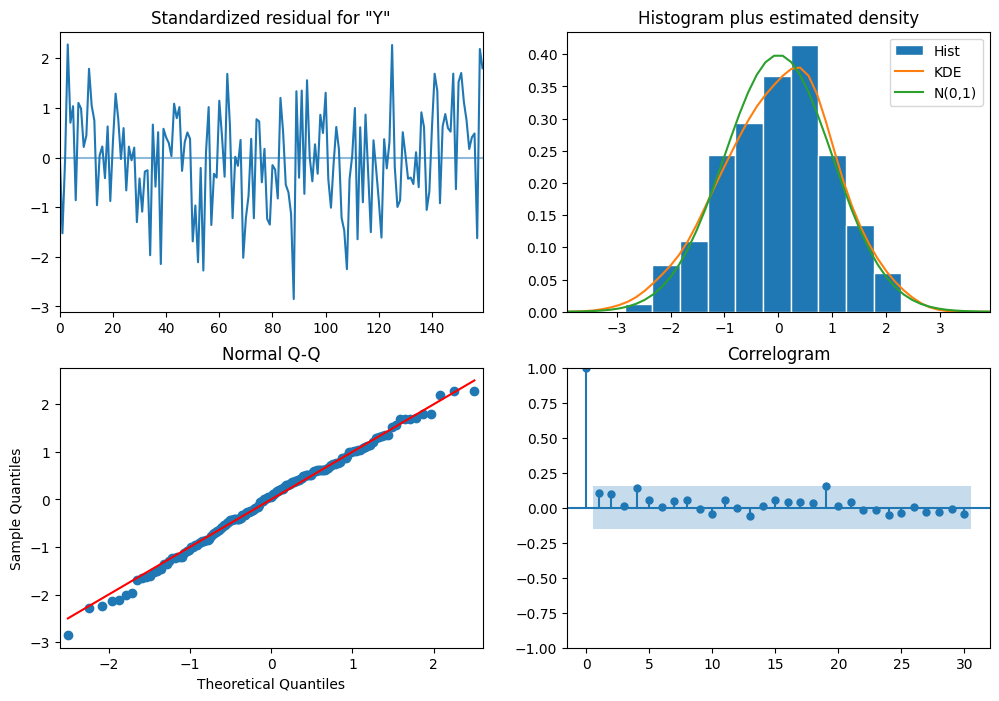

In [ ]:
train_ma1.plot_diagnostics(figsize=(12,8), lags=30); plt.show()

**Interpretasi Diagnostik Sisaan:**

Plot sisaan terstandarisasi bergerak acak di sekitar nol tanpa pola sistematis, mengindikasikan sisaan bersifat stasioner. Histogram dan kurva KDE mendekati bentuk kurva normal N(0,1), didukung oleh plot Normal Q-Q yang titik-titiknya mengikuti garis diagonal dengan baik (kecuali sedikit penyimpangan di ekor kiri). Correlogram menunjukkan tidak ada lag yang keluar dari batas signifikansi (kecuali lag 0), mengonfirmasi sisaan tidak berkorelasi. Secara keseluruhan, model MA(1) sudah memenuhi seluruh asumsi diagnostik sisaan.

In [ ]:
het_arch(train_ma1.resid, nlags=30)[1]

np.float64(0.4144696247112155)

In [ ]:
runstest_1samp(train_ma1.resid, correction=False)

(np.float64(0.07178238589288728), np.float64(0.9427750906757536))

In [ ]:
stat, p = shapiro(train_ma1.resid)
print(stat, p)

0.9931663213850672 0.6537289100375843


In [ ]:
# Model ARMA(1,1)
train_arma11_fit = ARIMA(train_arma11, order=(1,0,1)).fit()
print(train_arma11_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      Y   No. Observations:                  160
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -234.206
Date:                Wed, 23 Sep 2026   AIC                            476.412
Time:                        02:52:52   BIC                            488.713
Sample:                             0   HQIC                           481.407
                                - 160                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0155      0.171     -0.090      0.928      -0.352       0.321
ar.L1          0.2208      0.112      1.966      0.049       0.001       0.441
ma.L1          0.5816      0.092      6.337      0.0

**Interpretasi Model ARMA(1,1):**

Hasil fitting model ARMA(1,1) menunjukkan parameter φ₁ signifikan secara marginal (p-value = 0,049) dan θ₁ signifikan (p-value < 0,001), sedangkan konstanta tidak signifikan (p-value = 0,928). Nilai Ljung-Box (p-value = 0,97), uji heteroskedastisitas (p-value = 0,35), dan Jarque-Bera (p-value = 0,59) seluruhnya tidak signifikan pada taraf 5%, menunjukkan sisaan sudah memenuhi asumsi white noise, homoskedastis, dan menyebar normal — bahkan dengan hasil Ljung-Box yang jauh lebih baik dibandingkan model MA(1). Model menghasilkan AIC = 476,412 dan BIC = 488,713.


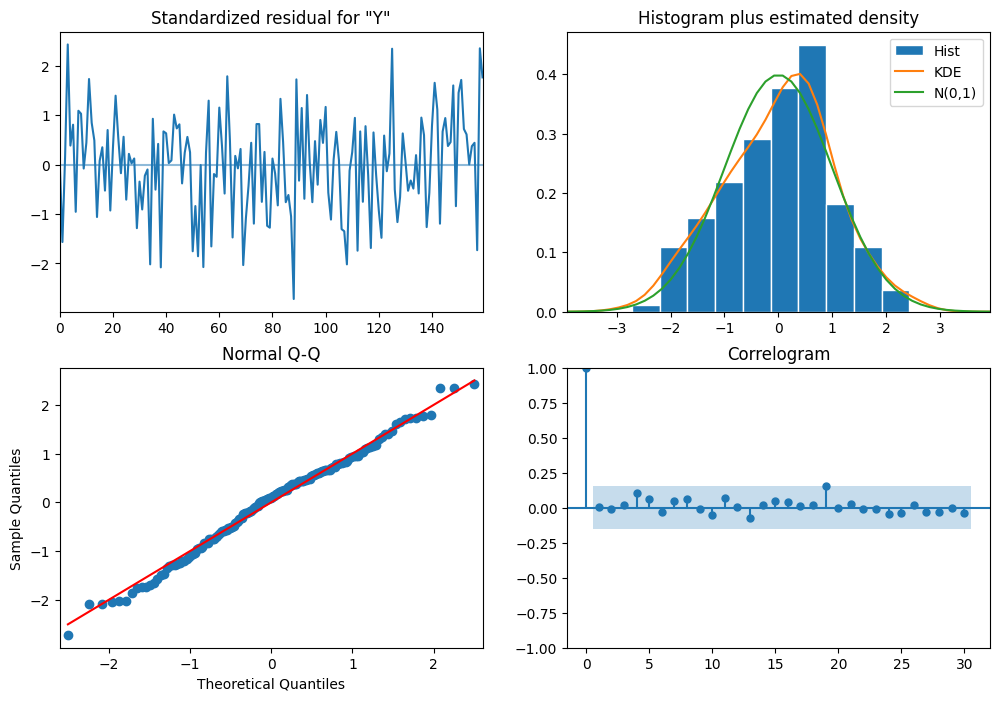

In [ ]:
train_arma11_fit.plot_diagnostics(figsize=(12,8), lags=30); plt.show()

**Interpretasi Diagnostik Sisaan:**

Plot sisaan terstandarisasi bergerak acak di sekitar nol tanpa pola sistematis, mengindikasikan sisaan bersifat stasioner. Histogram dan kurva KDE mendekati bentuk kurva normal N(0,1), didukung oleh plot Normal Q-Q yang titik-titiknya mengikuti garis diagonal dengan cukup baik (sedikit penyimpangan di kedua ekor). Correlogram menunjukkan tidak ada lag yang keluar dari batas signifikansi (kecuali lag 0), mengonfirmasi sisaan tidak berkorelasi. Secara keseluruhan, model ARMA(1,1) sudah memenuhi seluruh asumsi diagnostik sisaan, dengan kualitas sisaan yang sedikit lebih baik dibandingkan model MA(1).

In [ ]:
het_arch(train_arma11_fit.resid, nlags=30)[1]

np.float64(0.30665998146084955)

In [ ]:
runstest_1samp(train_arma11_fit.resid, correction=False)

(np.float64(0.48398726488083926), np.float64(0.6283949072052086))

In [ ]:
stat, p = shapiro(train_arma11_fit.resid)
print(stat, p)

0.9906176445299303 0.3723647482951017


In [ ]:
# TABEL AIC BIC
pd.DataFrame({'Model':['MA(1)','ARMA(1,1)'],
            'AIC':[train_ma1.aic, train_arma11_fit.aic],
            'BIC':[train_ma1.bic, train_arma11_fit.bic]})

,Model,AIC,BIC
0,MA(1),478.082951,487.308473
1,"ARMA(1,1)",476.412000,488.712695


Berdasarkan kriteria AIC, model ARMA(1,1) memiliki nilai lebih kecil (476,412) dibandingkan model MA(1) (478,083), sedangkan berdasarkan kriteria BIC, model MA(1) memiliki nilai lebih kecil (487,308) dibandingkan model ARMA(1,1) (488,713). Perbedaan hasil antara AIC dan BIC ini wajar terjadi karena BIC memberikan penalti lebih besar terhadap penambahan jumlah parameter model. Dengan mempertimbangkan hasil diagnostik sisaan yang menunjukkan model ARMA(1,1) memiliki nilai statistik Ljung-Box yang jauh lebih baik (p-value = 0,97) dibandingkan model MA(1) (p-value = 0,19), serta kesesuaiannya dengan model pembangkit data yang memang berbentuk ARMA(1,1), maka model ARMA(1,1) dipilih sebagai model terbaik untuk digunakan pada tahap peramalan.

In [ ]:
prediksi_test = train_arma11_fit.get_forecast(test_arma11.shape[0]).summary_frame(alpha=0.05)

In [ ]:
prediksi_test

Y,mean,mean_se,mean_ci_lower,mean_ci_upper
160,1.830138,1.043565,-0.215211,3.875488
161,0.392024,1.337982,-2.230372,3.014421
162,0.074505,1.350695,-2.572808,2.721818
163,0.004400,1.351311,-2.644122,2.652922
164,-0.011078,1.351342,-2.659659,2.637502
165,-0.014496,1.351343,-2.663079,2.634088
166,-0.015250,1.351343,-2.663834,2.633333
167,-0.015417,1.351343,-2.664001,2.633167
168,-0.015454,1.351343,-2.664037,2.633130
169,-0.015462,1.351343,-2.664046,2.633122


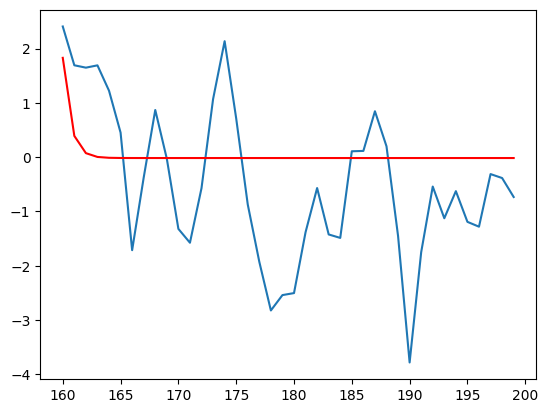

In [ ]:
test_arma11.plot()
prediksi_test['mean'].plot(color='red')
plt.show()

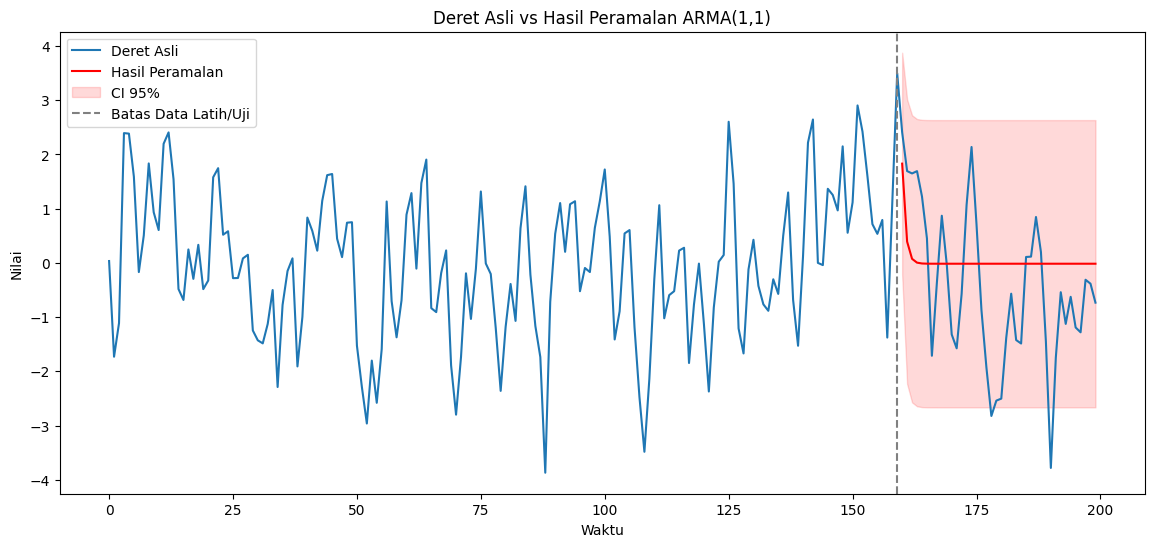

In [ ]:
plt.figure(figsize=(14,6))

# Plot deret asli (seluruh data, train + test)
plt.plot(df_arma11['Y'], label='Deret Asli')

# Plot hasil peramalan pada periode data uji
plt.plot(prediksi_test['mean'], color='red', label='Hasil Peramalan')

# Selang kepercayaan peramalan
plt.fill_between(prediksi_test.index,
                  prediksi_test['mean_ci_lower'],
                  prediksi_test['mean_ci_upper'],
                  color='red', alpha=.15, label='CI 95%')

plt.axvline(x=train_arma11.index[-1], color='gray', linestyle='--', label='Batas Data Latih/Uji')
plt.title('Deret Asli vs Hasil Peramalan ARMA(1,1)')
plt.xlabel('Waktu'); plt.ylabel('Nilai')
plt.legend()
plt.show()

Plot perbandingan deret asli dan hasil peramalan menunjukkan bahwa garis peramalan (merah) dengan cepat mendatar menuju nilai konstanta model (mendekati nol) setelah beberapa periode awal peramalan, sementara data aktual pada periode uji (biru) tetap berfluktuasi tajam mengikuti karakteristik deret ARMA(1,1) yang stasioner. Pola ini merupakan konsekuensi dari sifat mean-reverting model ARMA: karena tidak tersedia informasi baru (observasi aktual) untuk memperbarui prediksi pada horizon yang lebih jauh, peramalan secara bertahap menuju rata-rata proses jangka panjang. Selang kepercayaan 95% (area merah muda) melebar dan stabil seiring bertambahnya horizon peramalan, mencerminkan meningkatnya ketidakpastian pada peramalan multi-langkah ke depan. Meskipun secara visual pola peramalan tidak mengikuti fluktuasi data aktual, seluruh nilai aktual pada periode uji masih berada dalam selang kepercayaan 95% peramalan, sehingga model masih dapat dikatakan mampu menangkap rentang ketidakpastian data dengan baik, walaupun tidak menangkap pola fluktuasi jangka pendeknya. Kondisi ini sejalan dengan besarnya nilai MAPE data uji yang tinggi namun nilai RMSE yang masih berada pada rentang wajar sesuai skala variansi deret.

In [ ]:
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
import numpy as np

# Evaluasi pada data latih (fitted values vs aktual)
fitted_train = train_arma11_fit.fittedvalues
mape_train = mean_absolute_percentage_error(train_arma11, fitted_train) * 100
rmse_train = np.sqrt(mean_squared_error(train_arma11, fitted_train))

# Evaluasi pada data uji (forecast vs aktual)
mape_test = mean_absolute_percentage_error(test_arma11, prediksi_test['mean']) * 100
rmse_test = np.sqrt(mean_squared_error(test_arma11, prediksi_test['mean']))

print('MAPE Latih: ', mape_train, '%')
print('RMSE Latih: ', rmse_train)
print('MAPE Uji  : ', mape_test, '%')
print('RMSE Uji  : ', rmse_test)

MAPE Latih:  13434.033124724428 %
RMSE Latih:  1.0449306294089538
MAPE Uji  :  96.15118310433802 %
RMSE Uji  :  1.4186891566955826


Perhatikan bahwa nilai MAPE data uji sangat besar (96,15%). Berdasarkan plot perbandingan antara data uji dan hasil peramalan, tampak bahwa pola hasil peramalan cenderung mendatar menuju rata-rata proses, sementara nilai data uji tetap berfluktuasi mengikuti karakteristik deret ARMA(1,1) yang stasioner. Hal ini menyebabkan pada titik-titik waktu tertentu, nilai aktual berada sangat dekat dengan nol, sehingga nilai MAPE yang dihitung sebagai persentase terhadap nilai aktual menjadi sangat besar dan tidak representatif. Sedangkan nilai RMSE relatif kecil (1,4187), yang jika dibandingkan dengan skala variansi deret hasil simulasi (σ² ≈ 1,09) menunjukkan bahwa besar kesalahan peramalan masih berada pada rentang

##**Kesimpulan**


Berdasarkan hasil simulasi dan pemodelan deret waktu stasioner menggunakan **seed 170**, diperoleh bahwa proses identifikasi melalui ACF, PACF, dan EACF, yang dilanjutkan dengan pengepasan model, pemeriksaan diagnostik sisaan, overfitting, serta perbandingan AIC dan BIC, secara umum mampu mengidentifikasi model yang sesuai untuk masing-masing deret simulasi.

Pada deret **MA(1)** dengan $\theta = 0.6$ dan $n = 120$, model **MA(1)** terpilih sebagai model terbaik dengan nilai **AIC 285.407** dan **BIC 293.100**, lebih rendah dibandingkan model AR(1), MA(2), dan ARMA(1,1). Penambahan parameter pada model yang lebih kompleks juga tidak memberikan peningkatan yang memadai. Hasil evaluasi menghasilkan RMSE sebesar **1.0364 pada data latih** dan **1.0596 pada data uji**, yang menunjukkan kesalahan prediksi relatif konsisten antara kedua data.

Pada deret **AR(2)** dengan $\phi_1 = 0.9$, $\phi_2 = -0.5$, dan $n = 100$, hasil identifikasi dan perbandingan model mendukung **AR(2)** sebagai model terbaik dibandingkan model overfitting AR(3) dan ARMA(2,1). Model AR(2) menghasilkan **AIC 233.858** dan **BIC 243.386**. Nilai RMSE diperoleh sebesar **0.9915 pada data latih** dan **1.3719 pada data uji**, sehingga terdapat peningkatan kesalahan pada data uji dibandingkan data latih.

Sementara itu, pada deret **ARMA(1,1)** dengan $\phi = 0.4$, $\theta = 0.6$, dan $n = 200$, model MA(1) dan ARMA(1,1) sama-sama dipertimbangkan. Model ARMA(1,1) memiliki **AIC lebih rendah (476.412)** dibandingkan MA(1) (478.083), sedangkan MA(1) memiliki **BIC lebih rendah (487.308)** dibandingkan ARMA(1,1) (488.713). Dengan mempertimbangkan hasil diagnostik sisaan dan struktur model yang dianalisis, **ARMA(1,1) digunakan untuk peramalan**. Model tersebut menghasilkan RMSE sebesar **1.0449 pada data latih** dan **1.4187 pada data uji**.

Secara keseluruhan, hasil analisis menunjukkan bahwa **pemilihan model deret waktu tidak cukup hanya berdasarkan satu kriteria**, tetapi perlu mempertimbangkan pola ACF, PACF, dan EACF, signifikansi parameter, diagnostik sisaan, serta AIC dan BIC secara bersama-sama. Nilai MAPE pada ketiga simulasi juga perlu diinterpretasikan secara hati-hati karena deret berfluktuasi di sekitar nol, sehingga nilai aktual yang sangat kecil dapat menghasilkan persentase kesalahan yang sangat besar. Oleh karena itu, pada simulasi ini **MAPE tidak digunakan sebagai satu-satunya dasar penilaian kemampuan peramalan**, tetapi dibaca bersama RMSE dan hasil diagnostik model.